## Usage

# BasedTab

> Based Tabular Data

### Installation

Not on PyPI yet. Install:
```bash
git clone https://github.com/AnswerDotAI/basedtab.git
pip install -e .
```

## How to use

### Load data

`read_csv` and `save_csv`

In [ ]:
from basedtab.core import *
from nbdev.config import get_config

data_path = str(get_config().config_path/'data/toy.csv')
bf = BFrame.read_csv(data_path)
bf.head(3).df

,Number,City,Gender,Age,Income,Illness
0,1,Dallas,Male,41,40367.0,No
1,2,Dallas,Male,54,45084.0,No
2,3,Dallas,Male,42,52483.0,No


### Groupby

In [ ]:
from basedpl import add, tally, square
MEAN = add.reduce_first / tally
bf.groupby("City", "Income", mean=MEAN).df.astype(int)

,,Income
Dallas,mean,45252
New York City,mean,96857
Los Angeles,mean,95264
Mountain View,mean,135078
Boston,mean,91554
Washington D.C.,mean,70991
San Diego,mean,100756
Austin,mean,90277


In [ ]:
RMSE = MEAN.under(square)
bf.head(100).groupby("Gender", ["Age", "Income"], mean=MEAN, rmse=RMSE)

┌→───────────────────────────┐
↓"Male"⌷                     │
↓             Age      Income│
│mean 44.57407407 48301.42593│
│rmse 45.66970793 49632.10639│
│                            │
│"Female"⌷                   │
│             Age      Income│
│mean 45.30434783 39739.36957│
│rmse 46.73468128 40738.65853│
└~───────────────────────────┘

### Rolling

In [ ]:
ts = BFrame(dict(price=[5,4.3,4.1,2,10,20,15,25]))
ts

┌→────────────────────────────────┐
│ price:┌→──────────────────────┐ │
│       │5 4.3 4.1 2 10 20 15 25│ │
│       └~──────────────────────┘ │
└∊────────────────────────────────┘

In [ ]:
ts.rolling("price", size=3, edge="clamp", mean=MEAN).df

,,price
0,mean,4.766667
1,mean,4.466667
2,mean,3.466667
3,mean,5.366667
4,mean,10.666667
5,mean,15.000000
6,mean,20.000000
7,mean,21.666667


In [ ]:
ts.rolling("price", size=2, step=2, mean=MEAN, rmse=RMSE).df

price
0 mean   4.650000
  rmse   4.663153
1 mean   3.050000
  rmse   3.225678
2 mean  15.000000
  rmse  15.811388
3 mean  20.000000
  rmse  20.615528

### Plot

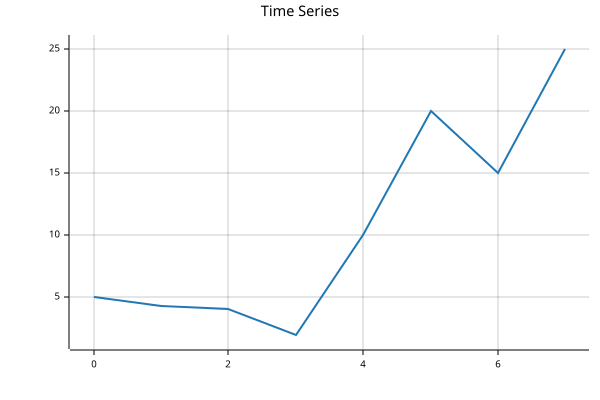

In [ ]:
ts.plot(title="Time Series")

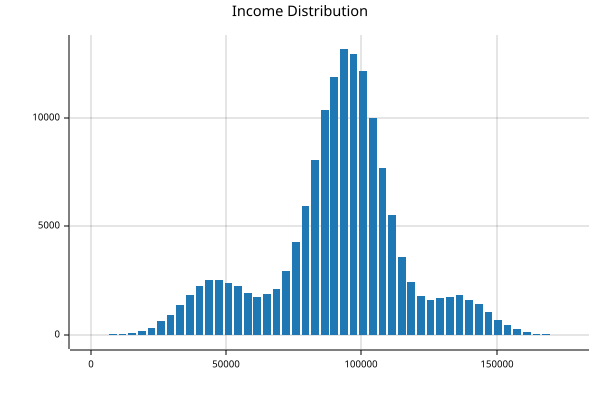

In [ ]:
bf["Income"].hist(title="Income Distribution")